# Olist Dashboard: Data Preparation
**CSE 578: Data Visualization · Olist E-Commerce Project**

This notebook reads the raw Olist tables for three departments, checks data quality, cleans and joins them,
and saves the analysis-ready files that the dashboard (`app.py`) loads.

| Department | Raw tables used | What the dashboard measures |
|---|---|---|
| Sales and Marketplace Operations | orders, order_items, products, category_translation, customers, sellers | Revenue, orders, average order value, categories, states, seller concentration |
| Logistics and Fulfillment | orders (timestamps), order_items (freight), sellers, customers, geolocation | Delivery time, promised vs actual, late rate, fulfillment stages, freight cost, routes |
| Customer Experience | order_reviews | Review scores, satisfaction trend, effect of late delivery on scores |

**Outputs** (in `visualization/processed/`):
- `orders.parquet`: one row per order, combining all three departments
- `order_items.parquet`: one row per item sold, for category and seller analysis
- `states.parquet`: Brazilian states with name, region and map coordinates

Raw data: `data/olist/` (download with `kaggle datasets download -d olistbr/brazilian-ecommerce -p data/olist --unzip`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "visualization" else Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "olist"
PROCESSED_DIR = PROJECT_DIR / "visualization" / "processed"
PROCESSED_DIR.mkdir(exist_ok=True)

if not RAW_DIR.exists():
    raise FileNotFoundError(f"{RAW_DIR} not found; download the Olist dataset first (see above)")

# Full months with enough orders to analyze. 2016 has only ~330 orders and
# September-October 2018 only 20, so they would distort monthly trends.
ANALYSIS_START = pd.Timestamp("2017-01-01")
ANALYSIS_END = pd.Timestamp("2018-09-01")  # exclusive

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Load the raw tables

In [2]:
RAW_FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "customers": "olist_customers_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
}

raw = {name: pd.read_csv(RAW_DIR / file_name) for name, file_name in RAW_FILES.items()}

for name, table in raw.items():
    print(f"{name:<22} {table.shape[0]:>9,} rows  {table.shape[1]:>2} columns")

orders                    99,441 rows   8 columns
order_items              112,650 rows   7 columns
products                  32,951 rows   9 columns
category_translation          71 rows   2 columns
customers                 99,441 rows   5 columns
sellers                    3,095 rows   4 columns
geolocation            1,000,163 rows   5 columns
reviews                   99,224 rows   7 columns


## 2. Data quality checks
Before cleaning, check each table for missing values and duplicate rows.

In [3]:
quality = pd.DataFrame({
    "rows": {name: len(table) for name, table in raw.items()},
    "missing_cells": {name: int(table.isna().sum().sum()) for name, table in raw.items()},
    "duplicate_rows": {name: int(table.duplicated().sum()) for name, table in raw.items()},
})
quality

,rows,missing_cells,duplicate_rows
orders,99441,4908,0
order_items,112650,0,0
products,32951,2448,0
category_translation,71,0,0
customers,99441,0,0
sellers,3095,0,0
geolocation,1000163,0,261831
reviews,99224,145903,0


In [4]:
print("Missing values per column (only columns with gaps):\n")
for name, table in raw.items():
    missing = table.isna().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print(f"[{name}]")
        print(missing.to_string(), end="\n\n")

Missing values per column (only columns with gaps):

[orders]
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

[products]
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2

[reviews]
review_comment_title      87656
review_comment_message    58247



In [5]:
orders_raw = raw["orders"]
reviews_raw = raw["reviews"]
products_raw = raw["products"]
translated = set(raw["category_translation"]["product_category_name"])

print("Order status counts:")
print(orders_raw["order_status"].value_counts().to_string(), end="\n\n")
print(f"Orders with more than one review:     {reviews_raw['order_id'].duplicated().sum():,}")
print(f"Products with no category:            {products_raw['product_category_name'].isna().sum():,}")
print(f"Categories missing from translation:  {sorted(set(products_raw['product_category_name'].dropna()) - translated)}")
print(f"Delivered orders with no delivery date: "
      f"{((orders_raw['order_status'] == 'delivered') & orders_raw['order_delivered_customer_date'].isna()).sum()}")
print("\nOrders per purchase month:")
print(pd.to_datetime(orders_raw["order_purchase_timestamp"]).dt.to_period("M").value_counts().sort_index().to_string())

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

Orders with more than one review:     551
Products with no category:            610
Categories missing from translation:  ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


Delivered orders with no delivery date: 8

Orders per purchase month:
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


**Findings and how they are handled:**

| Issue | Handling |
|---|---|
| Missing delivery timestamps on undelivered or canceled orders | Expected. Delivery metrics use only delivered orders. |
| Some orders have several reviews | Keep the most recently answered review per order. |
| 610 products have no category; 2 categories are missing from the translation file | Label as "Unknown"; translate the two missing names manually. |
| Very few orders in 2016 and after August 2018 | Keep January 2017 to August 2018 (20 full months). |
| Geolocation has many duplicate rows and a few points outside Brazil | Keep only points inside Brazil's bounding box and use the median per state. |
| Review comments are optional | Record whether a comment exists; the text itself is in Portuguese and is not analyzed. |

## 3. Reference data: states and regions

In [6]:
STATES = [
    # code, name, region
    ("AC", "Acre", "North"), ("AP", "Amapá", "North"), ("AM", "Amazonas", "North"),
    ("PA", "Pará", "North"), ("RO", "Rondônia", "North"), ("RR", "Roraima", "North"),
    ("TO", "Tocantins", "North"),
    ("AL", "Alagoas", "Northeast"), ("BA", "Bahia", "Northeast"), ("CE", "Ceará", "Northeast"),
    ("MA", "Maranhão", "Northeast"), ("PB", "Paraíba", "Northeast"), ("PE", "Pernambuco", "Northeast"),
    ("PI", "Piauí", "Northeast"), ("RN", "Rio Grande do Norte", "Northeast"), ("SE", "Sergipe", "Northeast"),
    ("DF", "Distrito Federal", "Central-West"), ("GO", "Goiás", "Central-West"),
    ("MT", "Mato Grosso", "Central-West"), ("MS", "Mato Grosso do Sul", "Central-West"),
    ("ES", "Espírito Santo", "Southeast"), ("MG", "Minas Gerais", "Southeast"),
    ("RJ", "Rio de Janeiro", "Southeast"), ("SP", "São Paulo", "Southeast"),
    ("PR", "Paraná", "South"), ("RS", "Rio Grande do Sul", "South"), ("SC", "Santa Catarina", "South"),
]
states = pd.DataFrame(STATES, columns=["state", "state_name", "region"])
STATE_TO_REGION = dict(zip(states["state"], states["region"]))

# Map position of each state: median of its postal-code coordinates, inside Brazil's bounding box.
geo = raw["geolocation"]
geo = geo[geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)]
centroids = (
    geo.groupby("geolocation_state")[["geolocation_lat", "geolocation_lng"]]
    .median()
    .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"})
)
states = states.merge(centroids, left_on="state", right_index=True, how="left")

if states[["lat", "lng"]].isna().any().any():
    raise ValueError("Some states have no geolocation coordinates")
states

,state,state_name,region,lat,lng
0,AC,Acre,North,-9.962046,-67.830638
1,AP,Amapá,North,0.031212,-51.074329
2,AM,Amazonas,North,-3.089704,-60.011998
3,PA,Pará,North,-1.462892,-48.484245
4,RO,Rondônia,North,-10.431416,-63.021605
5,RR,Roraima,North,2.823026,-60.698431
6,TO,Tocantins,North,-10.181896,-48.326965
7,AL,Alagoas,Northeast,-9.636922,-35.754056
8,BA,Bahia,Northeast,-12.956340,-38.957697
9,CE,Ceará,Northeast,-3.789734,-38.585162


## 4. Sales and Marketplace Operations
Build one row per item with its English category and the seller's location, then total the items per order.
**Order value = product price + freight**, the total the customer paid.

In [7]:
# The translation file lacks two Portuguese category names, so translate them here.
MISSING_TRANSLATIONS = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
}

products = products_raw.merge(raw["category_translation"], on="product_category_name", how="left")
products["category"] = (
    products["product_category_name_english"]
    .fillna(products["product_category_name"].map(MISSING_TRANSLATIONS))
    .fillna("unknown")
    .str.replace("_", " ")
    .str.capitalize()
)

items = (
    raw["order_items"]
    .merge(products[["product_id", "category"]], on="product_id", how="left", validate="many_to_one")
    .merge(raw["sellers"][["seller_id", "seller_state"]], on="seller_id", how="left", validate="many_to_one")
)
items["item_value"] = items["price"] + items["freight_value"]

order_totals = items.groupby("order_id").agg(
    item_count=("order_item_id", "count"),
    product_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    order_value=("item_value", "sum"),
    seller_count=("seller_id", "nunique"),
)

# An order's main category and seller come from its most expensive item.
main_item = (
    items.sort_values("price", ascending=False)
    .drop_duplicates("order_id")
    .set_index("order_id")[["category", "seller_id", "seller_state"]]
    .rename(columns={"category": "main_category", "seller_id": "main_seller_id"})
)

print(f"Items: {len(items):,}   Orders with items: {len(order_totals):,}   Categories: {items['category'].nunique()}")
order_totals.describe().round(2)

Items: 112,650   Orders with items: 98,666   Categories: 74


,item_count,product_value,freight_value,order_value,seller_count
count,98666.00,98666.00,98666.00,98666.00,98666.00
mean,1.14,137.75,22.82,160.58,1.01
std,0.54,210.65,21.65,220.47,0.12
min,1.00,0.85,0.00,9.59,1.00
25%,1.00,45.90,13.85,61.98,1.00
50%,1.00,86.90,17.17,105.29,1.00
75%,1.00,149.90,24.04,176.87,1.00
max,21.00,13440.00,1794.96,13664.08,5.00


## 5. Logistics and Fulfillment
Each order passes through four timestamps: **purchase → payment approval → handed to carrier → delivered**, plus the delivery date promised at checkout.

- `delivery_days`: purchase to delivery (actual)
- `estimated_days`: purchase to promised date
- `delay_days`: delivery date minus promised date (positive = late)
- Stage durations: `approval_days`, `handling_days` (seller prepares and ships), `transit_days` (carrier)

In [8]:
TIMESTAMP_COLUMNS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = orders_raw.copy()
for column in TIMESTAMP_COLUMNS:
    orders[column] = pd.to_datetime(orders[column])

orders = orders.rename(columns={
    "order_purchase_timestamp": "purchase_ts",
    "order_approved_at": "approved_ts",
    "order_delivered_carrier_date": "carrier_ts",
    "order_delivered_customer_date": "delivered_ts",
    "order_estimated_delivery_date": "estimated_ts",
})


def days_between(start: pd.Series, end: pd.Series) -> pd.Series:
    return (end - start).dt.total_seconds() / 86_400


orders["delivery_days"] = days_between(orders["purchase_ts"], orders["delivered_ts"])
orders["estimated_days"] = days_between(orders["purchase_ts"], orders["estimated_ts"])
orders["delay_days"] = (orders["delivered_ts"].dt.normalize() - orders["estimated_ts"]).dt.days
orders["approval_days"] = days_between(orders["purchase_ts"], orders["approved_ts"])
orders["handling_days"] = days_between(orders["approved_ts"], orders["carrier_ts"])
orders["transit_days"] = days_between(orders["carrier_ts"], orders["delivered_ts"])

# A few orders have timestamps out of order (e.g. handed to carrier before approval).
# Those stage durations are recording errors, so drop them rather than average negative days.
STAGE_COLUMNS = ["approval_days", "handling_days", "transit_days"]
for column in STAGE_COLUMNS:
    negative = orders[column] < 0
    print(f"{column:<15} negative values set to missing: {negative.sum():,}")
    orders.loc[negative, column] = np.nan

orders["is_delivered"] = (orders["order_status"] == "delivered") & orders["delivered_ts"].notna()
orders["is_late"] = (orders["delay_days"] > 0).where(orders["is_delivered"]).astype("boolean")

DELAY_BUCKETS = [
    "15+ days early", "8–14 days early", "1–7 days early", "On promised day",
    "1–3 days late", "4–7 days late", "8–14 days late", "15+ days late",
]
orders["delay_bucket"] = pd.cut(
    orders["delay_days"].where(orders["is_delivered"]),
    bins=[-np.inf, -15, -8, -1, 0, 3, 7, 14, np.inf],
    labels=DELAY_BUCKETS,
)

orders.loc[orders["is_delivered"], ["delivery_days", "estimated_days", "delay_days", *STAGE_COLUMNS]].describe().round(1)

approval_days   negative values set to missing: 0
handling_days   negative values set to missing: 1,359
transit_days    negative values set to missing: 23


,delivery_days,estimated_days,delay_days,approval_days,handling_days,transit_days
count,96470.0,96470.0,96470.0,96456.0,95105.0,96446.0
mean,12.6,23.7,-11.9,0.4,2.9,9.3
std,9.5,8.8,10.2,0.9,3.5,8.8
min,0.5,2.0,-147.0,0.0,0.0,0.0
25%,6.8,18.3,-17.0,0.0,0.9,4.1
50%,10.2,23.2,-12.0,0.0,1.8,7.1
75%,15.7,28.4,-7.0,0.6,3.6,12.0
max,209.6,155.1,188.0,30.9,125.8,205.2


## 6. Customer Experience
Keep the latest answered review for each order, and record whether the customer wrote a comment and how many days they took to answer the survey.

In [9]:
reviews = reviews_raw.copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews = reviews.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
reviews["has_comment"] = reviews["review_comment_message"].notna()
reviews["review_response_days"] = days_between(reviews["review_creation_date"], reviews["review_answer_timestamp"])

reviews = reviews.set_index("order_id")[["review_score", "has_comment", "review_response_days"]]
print(f"Orders with a review: {len(reviews):,}")
reviews["review_score"].value_counts().sort_index()

Orders with a review: 98,673


review_score
1    11363
2     3131
3     8133
4    19038
5    57008
Name: count, dtype: int64

## 7. Combine into one order-level table
Join sales totals, logistics measures, customer location and review to each order, then keep the analysis window.
An order counts as a **sale** unless it was canceled or unavailable.

In [10]:
customers = raw["customers"].copy()
customers["customer_region"] = customers["customer_state"].map(STATE_TO_REGION)

fact = (
    orders
    .merge(customers, on="customer_id", how="left", validate="one_to_one")
    .merge(order_totals, left_on="order_id", right_index=True, how="left")
    .merge(main_item, left_on="order_id", right_index=True, how="left")
    .merge(reviews, left_on="order_id", right_index=True, how="left")
)

fact = fact[(fact["purchase_ts"] >= ANALYSIS_START) & (fact["purchase_ts"] < ANALYSIS_END)].copy()

fact["purchase_month"] = fact["purchase_ts"].dt.to_period("M").dt.to_timestamp()
fact["purchase_weekday"] = fact["purchase_ts"].dt.day_name()
fact["purchase_hour"] = fact["purchase_ts"].dt.hour
fact["is_sale"] = ~fact["order_status"].isin(["canceled", "unavailable"])
fact["is_interstate"] = (fact["seller_state"] != fact["customer_state"]).where(fact["seller_state"].notna()).astype("boolean")
fact["freight_share"] = fact["freight_value"] / fact["order_value"]
fact["main_category"] = fact["main_category"].fillna("No items")

for column in ["item_count", "product_value", "freight_value", "order_value", "seller_count"]:
    fact[column] = fact[column].fillna(0)
fact["has_comment"] = fact["has_comment"].astype("boolean")

FACT_COLUMNS = [
    # identity and customer
    "order_id", "customer_id", "customer_unique_id", "customer_city", "customer_state", "customer_region",
    # sales
    "order_status", "is_sale", "purchase_ts", "purchase_month", "purchase_weekday", "purchase_hour",
    "item_count", "product_value", "freight_value", "order_value", "freight_share",
    "main_category", "seller_count", "main_seller_id", "seller_state", "is_interstate",
    # logistics
    "approved_ts", "carrier_ts", "delivered_ts", "estimated_ts", "is_delivered", "is_late",
    "delivery_days", "estimated_days", "delay_days", "delay_bucket",
    "approval_days", "handling_days", "transit_days",
    # customer experience
    "review_score", "has_comment", "review_response_days",
]
fact = fact[FACT_COLUMNS].reset_index(drop=True)

if fact["order_id"].duplicated().any():
    raise ValueError("orders table must have one row per order")
if fact["customer_region"].isna().any():
    raise ValueError("Some customer states are missing from the region table")

print(f"Orders in analysis window: {len(fact):,}  ({fact['purchase_month'].min():%b %Y} – {fact['purchase_month'].max():%b %Y})")
fact.head()

Orders in analysis window: 99,092  (Jan 2017 – Aug 2018)


,order_id,customer_id,customer_unique_id,customer_city,customer_state,customer_region,order_status,is_sale,purchase_ts,purchase_month,purchase_weekday,purchase_hour,item_count,product_value,freight_value,...,carrier_ts,delivered_ts,estimated_ts,is_delivered,is_late,delivery_days,estimated_days,delay_days,delay_bucket,approval_days,handling_days,transit_days,review_score,has_comment,review_response_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,Southeast,delivered,True,2017-10-02 10:56:33,2017-10-01,Monday,10,1.0,29.99,8.72,...,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,True,False,8.436574,15.544063,-8.0,8–14 days early,0.007431,2.366493,6.062650,4.0,True,1.155417
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,barreiras,BA,Northeast,delivered,True,2018-07-24 20:41:37,2018-07-01,Tuesday,20,1.0,118.70,22.76,...,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,True,False,13.782037,19.137766,-6.0,1–7 days early,1.279745,0.462882,12.039410,4.0,True,0.776273
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,Central-West,delivered,True,2018-08-08 08:38:49,2018-08-01,Wednesday,8,1.0,159.90,19.22,...,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,True,False,9.394213,26.639711,-18.0,15+ days early,0.011505,0.204595,9.178113,5.0,False,4.797199
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,Northeast,delivered,True,2017-11-18 19:28:06,2017-11-01,Saturday,19,1.0,45.00,27.20,...,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,True,False,13.208750,26.188819,-13.0,8–14 days early,0.012419,3.745833,9.450498,5.0,True,2.806921
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,Southeast,delivered,True,2018-02-13 21:18:39,2018-02-01,Tuesday,21,1.0,19.90,8.72,...,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,True,False,2.873877,12.112049,-10.0,8–14 days early,0.042940,0.893113,1.937824,5.0,False,1.543646


In [11]:
# Item-level table for category and seller analysis, carrying the order fields the dashboard filters on.
order_context = fact[["order_id", "purchase_month", "customer_state", "customer_region", "is_sale", "main_category"]]
items_fact = items.merge(order_context, on="order_id", how="inner")[[
    "order_id", "order_item_id", "purchase_month", "customer_state", "customer_region", "is_sale", "main_category",
    "product_id", "category", "seller_id", "seller_state", "price", "freight_value", "item_value",
]]
print(f"Items in analysis window: {len(items_fact):,}")

Items in analysis window: 112,279


## 8. Save the analysis-ready files

In [12]:
fact.to_parquet(PROCESSED_DIR / "orders.parquet", index=False)
items_fact.to_parquet(PROCESSED_DIR / "order_items.parquet", index=False)
states.to_parquet(PROCESSED_DIR / "states.parquet", index=False)

for path in sorted(PROCESSED_DIR.glob("*.parquet")):
    print(f"{path.name:<22} {path.stat().st_size / 1_048_576:5.1f} MB")

order_items.parquet      5.9 MB
orders.parquet          19.1 MB
states.parquet           0.0 MB


## 9. First look at the prepared data
A quick check of the headline numbers before building the dashboard. The full interactive analysis is in `app.py`.

In [13]:
sales = fact[fact["is_sale"]]
delivered = fact[fact["is_delivered"]]
reviewed = fact[fact["review_score"].notna()]

print("SALES AND MARKETPLACE OPERATIONS")
print(f"  Revenue (product + freight): R$ {sales['order_value'].sum():,.0f}")
print(f"  Orders:                      {len(sales):,}")
print(f"  Average order value:         R$ {sales['order_value'].mean():,.2f}")
print(f"  Unique customers:            {sales['customer_unique_id'].nunique():,}")
top_state = sales.groupby("customer_state")["order_value"].sum().sort_values(ascending=False)
print(f"  Top state by revenue:        {top_state.index[0]} ({top_state.iloc[0] / top_state.sum():.0%} of revenue)")

print("\nLOGISTICS AND FULFILLMENT")
print(f"  Delivered orders:            {len(delivered):,}")
print(f"  Average delivery time:       {delivered['delivery_days'].mean():.1f} days (promised {delivered['estimated_days'].mean():.1f})")
print(f"  Late delivery rate:          {delivered['is_late'].mean():.1%}")
print(f"  Freight share of order value:{sales['freight_share'].mean():>6.1%}")

print("\nCUSTOMER EXPERIENCE")
print(f"  Average review score:        {reviewed['review_score'].mean():.2f} / 5")
on_time_score = reviewed.loc[reviewed["is_late"] == False, "review_score"].mean()
late_score = reviewed.loc[reviewed["is_late"] == True, "review_score"].mean()
print(f"  Score when on time:          {on_time_score:.2f}")
print(f"  Score when late:             {late_score:.2f}")

SALES AND MARKETPLACE OPERATIONS
  Revenue (product + freight): R$ 15,683,707
  Orders:                      97,910
  Average order value:         R$ 160.18
  Unique customers:            94,707
  Top state by revenue:        SP (37% of revenue)

LOGISTICS AND FULFILLMENT
  Delivered orders:            96,203
  Average delivery time:       12.5 days (promised 23.6)
  Late delivery rate:          6.8%
  Freight share of order value: 20.9%

CUSTOMER EXPERIENCE
  Average review score:        4.09 / 5
  Score when on time:          4.29
  Score when late:             2.27


In [14]:
region_summary = (
    fact.groupby("customer_region")
    .agg(
        orders=("order_id", "count"),
        revenue=("order_value", "sum"),
        avg_delivery_days=("delivery_days", "mean"),
        late_rate=("is_late", "mean"),
        avg_review=("review_score", "mean"),
    )
    .sort_values("orders", ascending=False)
    .round({"revenue": 0, "avg_delivery_days": 1, "late_rate": 3, "avg_review": 2})
)
region_summary

,orders,revenue,avg_delivery_days,late_rate,avg_review
customer_region,,,,,
Southeast,68033,10196492.0,10.7,0.061,4.11
South,14091,2287114.0,14.0,0.059,4.14
Northeast,9359,1873489.0,20.0,0.128,3.89
Central-West,5764,1020205.0,15.0,0.065,4.07
North,1845,408904.0,22.6,0.086,3.96


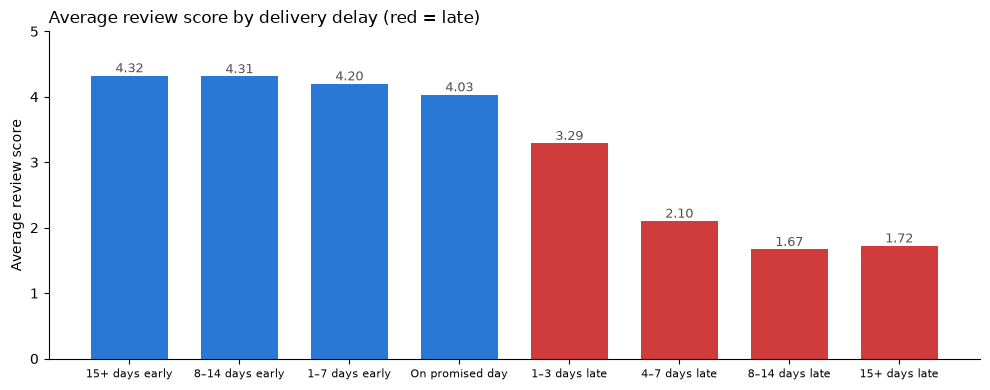

,mean,count
delay_bucket,,
15+ days early,4.32,34526
8–14 days early,4.31,36147
1–7 days early,4.20,17229
On promised day,4.03,1280
1–3 days late,3.29,1851
4–7 days late,2.10,1748
8–14 days late,1.67,1446
15+ days late,1.72,1333


In [15]:
# The cross-department question: how does delivery delay affect the review score?
score_by_delay = reviewed.groupby("delay_bucket", observed=True)["review_score"].agg(["mean", "count"])

late_buckets = [bucket for bucket in DELAY_BUCKETS if bucket.endswith("late")]
colors = ["#d03b3b" if bucket in late_buckets else "#2a78d6" for bucket in score_by_delay.index]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(score_by_delay.index, score_by_delay["mean"], color=colors, width=0.7)
for x, value in enumerate(score_by_delay["mean"]):
    ax.text(x, value + 0.05, f"{value:.2f}", ha="center", fontsize=9, color="#52514e")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score")
ax.set_title("Average review score by delivery delay (red = late)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

score_by_delay.round(2)